# DSCI 552 – Homework 8
**Name:** Tina Arezoomanians

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

### 1(a) Data Preparation

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix
)
from sklearn.pipeline import Pipeline

In [3]:
# Load the Breast Cancer Wisconsin dataset
columns = ['ID', 'Diagnosis'] + [f'Feature_{i}' for i in range(1, 31)]

df = pd.read_csv('data/wdbc.data', header=None, names=columns)

print("Dataset shape:", df.shape)
display(df.head())

print("\nClass distribution:")
print(df['Diagnosis'].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

Dataset shape: (569, 32)


,ID,Diagnosis,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,...,Feature_21,Feature_22,Feature_23,Feature_24,Feature_25,Feature_26,Feature_27,Feature_28,Feature_29,Feature_30
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Class distribution:
Diagnosis
B    357
M    212
Name: count, dtype: int64

Missing values: 0


### 1(b) Monte Carlo Simulation

The experiments are repeated 30 times using stratified
80/20 training and testing splits. Malignant cases are
encoded as 1 and benign cases as 0.

In [4]:
# Separate input features and target labels
X = df.drop(columns=['ID', 'Diagnosis']).to_numpy()
y = df['Diagnosis'].map({'B': 0, 'M': 1}).to_numpy()

# Number of Monte Carlo runs
M = 30

# Penalty parameter candidates
C_values = np.logspace(-3, 3, 13)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Monte Carlo runs:", M)
print("C values:", C_values)

Feature matrix shape: (569, 30)
Target shape: (569,)
Monte Carlo runs: 30
C values: [1.00000000e-03 3.16227766e-03 1.00000000e-02 3.16227766e-02
 1.00000000e-01 3.16227766e-01 1.00000000e+00 3.16227766e+00
 1.00000000e+01 3.16227766e+01 1.00000000e+02 3.16227766e+02
 1.00000000e+03]


#### 1(b)(i) Supervised Learning

An L1-penalized linear SVM is trained using the labeled
training data. Features are standardized, and the optimal
penalty parameter C is selected using 5-fold stratified
cross-validation.

In [10]:
# Calculate classification performance metrics
def calculate_metrics(y_true, y_pred, y_score):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'AUC': roc_auc_score(y_true, y_score)
    }


# Train an L1-penalized SVM using 5-fold cross-validation
def train_l1_svm(X_train, y_train, seed):
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', LinearSVC(
            penalty='l1',
            loss='squared_hinge',
            dual=False,
            max_iter=100000,
            tol=1e-3,
            random_state=seed
        ))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    grid = GridSearchCV(
        pipeline,
        param_grid={'svm__C': C_values},
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    return grid.best_estimator_, grid.best_params_['svm__C']

In [11]:
supervised_train_results = []
supervised_test_results = []
supervised_best_C = []

for run in range(M):
    # Stratified 80/20 train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=run
    )

    # Train SVM using 5-fold cross-validation
    model, best_C = train_l1_svm(X_train, y_train, run)
    supervised_best_C.append(best_C)

    # Training predictions
    y_train_pred = model.predict(X_train)
    y_train_score = model.decision_function(X_train)

    # Testing predictions
    y_test_pred = model.predict(X_test)
    y_test_score = model.decision_function(X_test)

    # Store performance metrics
    supervised_train_results.append(
        calculate_metrics(y_train, y_train_pred, y_train_score)
    )

    supervised_test_results.append(
        calculate_metrics(y_test, y_test_pred, y_test_score)
    )

    # Save first run for ROC curves and confusion matrices
    if run == 0:
        supervised_example = {
            'y_train': y_train,
            'y_train_pred': y_train_pred,
            'y_train_score': y_train_score,
            'y_test': y_test,
            'y_test_pred': y_test_pred,
            'y_test_score': y_test_score
        }

print("Completed all 30 supervised learning runs.")

Completed all 30 supervised learning runs.


In [9]:
supervised_summary = pd.DataFrame({
    'Training': pd.DataFrame(supervised_train_results).mean(),
    'Testing': pd.DataFrame(supervised_test_results).mean()
})

display(supervised_summary.round(4))

,Training,Testing
Accuracy,0.9853,0.9678
Precision,0.9912,0.9727
Recall,0.9694,0.9397
F1 Score,0.9802,0.9555
AUC,0.9972,0.9937


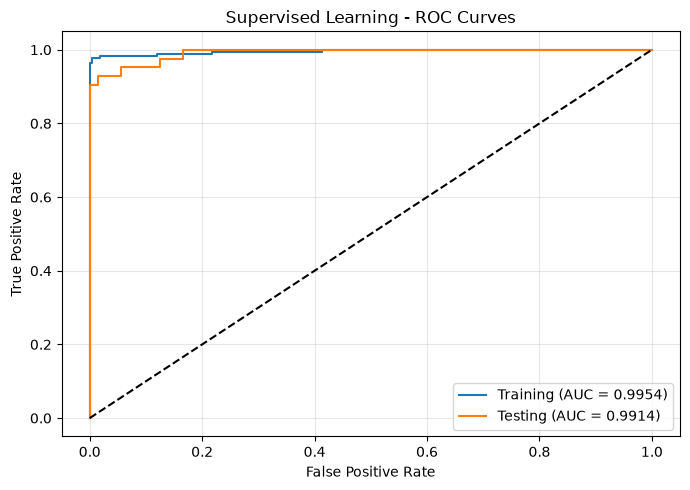

In [12]:
# ROC curves for the first Monte Carlo run
def plot_roc_curves(example, title):
    plt.figure(figsize=(7, 5))

    for split, label in [('train', 'Training'), ('test', 'Testing')]:
        y_true = example[f'y_{split}']
        y_score = example[f'y_{split}_score']

        fpr, tpr, _ = roc_curve(y_true, y_score)
        auc = roc_auc_score(y_true, y_score)

        plt.plot(fpr, tpr, label=f'{label} (AUC = {auc:.4f})')

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_roc_curves(supervised_example, 'Supervised Learning - ROC Curves')

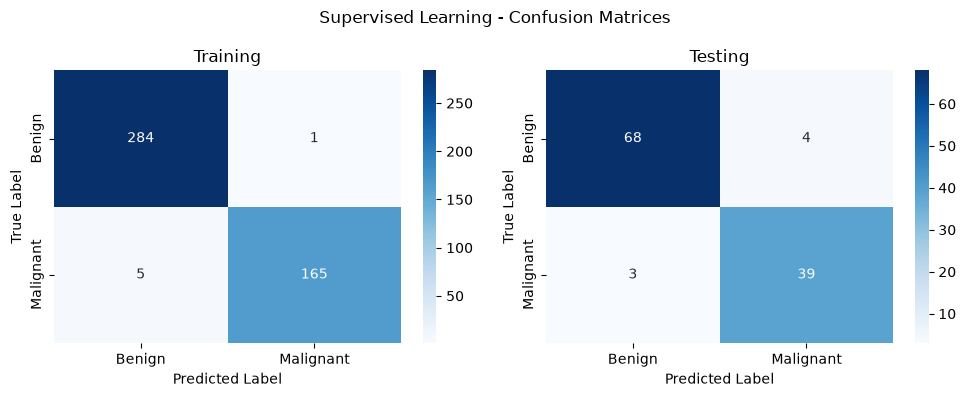

In [13]:
# Confusion matrices for the first Monte Carlo run
def plot_confusion_matrices(example, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for ax, split, label in zip(
        axes, ['train', 'test'], ['Training', 'Testing']
    ):
        cm = confusion_matrix(
            example[f'y_{split}'],
            example[f'y_{split}_pred']
        )

        sns.heatmap(
            cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'],
            ax=ax
        )

        ax.set_title(label)
        ax.set_xlabel('Predicted Label')
        ax.set_ylabel('True Label')

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_confusion_matrices(
    supervised_example,
    'Supervised Learning - Confusion Matrices'
)

**Interpretation:**

After 30 Monte Carlo runs, the supervised SVM had an average training accuracy of 98.53% and testing accuracy of 96.78%. The average F1-score and AUC for the test set were 0.9555 and 0.9937, respectively.

Both ROC curves are close to the upper-left corner, showing that the model performs well. In the first run, only 6 training samples and 7 testing samples were classified incorrectly. Since the training and testing results are fairly close, the model appears to generalize well to new data.

#### 1(b)(ii) Semi-Supervised Learning (Self-Training)

I started with 50% of each class as labeled data and left
the remaining samples unlabeled. After training the SVM,
I selected the unlabeled sample farthest from the decision
boundary, predicted its label, and added it to the labeled
set. I repeated this process until all samples were labeled.

In [14]:
def train_semi_supervised_svm(X_train, y_train, seed):
    # Select 50% of each class as labeled data
    X_labeled, X_unlabeled, y_labeled, _ = train_test_split(
        X_train, y_train,
        test_size=0.5,
        stratify=y_train,
        random_state=seed
    )

    # Select the best C using 5-fold cross-validation
    model, best_C = train_l1_svm(X_labeled, y_labeled, seed)

    # Self-training
    while len(X_unlabeled) > 0:

        # Find the sample farthest from the decision boundary
        distances = np.abs(model.decision_function(X_unlabeled))
        idx = np.argmax(distances)

        sample = X_unlabeled[idx:idx + 1]
        predicted_label = model.predict(sample)

        # Add the sample and its predicted label
        X_labeled = np.vstack([X_labeled, sample])
        y_labeled = np.concatenate([y_labeled, predicted_label])

        # Remove the sample from the unlabeled set
        X_unlabeled = np.delete(X_unlabeled, idx, axis=0)

        # Retrain the model
        model.fit(X_labeled, y_labeled)

    return model, best_C

In [15]:
semi_train_results = []
semi_test_results = []
semi_best_C = []

for run in range(M):
    # Use the same splits as supervised learning
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=run
    )

    model, best_C = train_semi_supervised_svm(
        X_train, y_train, run
    )
    semi_best_C.append(best_C)

    # Training results
    y_train_pred = model.predict(X_train)
    y_train_score = model.decision_function(X_train)

    # Testing results
    y_test_pred = model.predict(X_test)
    y_test_score = model.decision_function(X_test)

    semi_train_results.append(
        calculate_metrics(y_train, y_train_pred, y_train_score)
    )

    semi_test_results.append(
        calculate_metrics(y_test, y_test_pred, y_test_score)
    )

    # Save the first run for plots
    if run == 0:
        semi_example = {
            'y_train': y_train,
            'y_train_pred': y_train_pred,
            'y_train_score': y_train_score,
            'y_test': y_test,
            'y_test_pred': y_test_pred,
            'y_test_score': y_test_score
        }

    print(f"Run {run + 1}/{M} completed")

Run 1/30 completed
Run 2/30 completed
Run 3/30 completed
Run 4/30 completed
Run 5/30 completed
Run 6/30 completed
Run 7/30 completed
Run 8/30 completed
Run 9/30 completed
Run 10/30 completed
Run 11/30 completed
Run 12/30 completed
Run 13/30 completed
Run 14/30 completed
Run 15/30 completed
Run 16/30 completed
Run 17/30 completed
Run 18/30 completed
Run 19/30 completed
Run 20/30 completed
Run 21/30 completed
Run 22/30 completed
Run 23/30 completed
Run 24/30 completed
Run 25/30 completed
Run 26/30 completed
Run 27/30 completed
Run 28/30 completed
Run 29/30 completed
Run 30/30 completed


In [16]:
semi_summary = pd.DataFrame({
    'Training': pd.DataFrame(semi_train_results).mean(),
    'Testing': pd.DataFrame(semi_test_results).mean()
})

display(semi_summary.round(4))

,Training,Testing
Accuracy,0.9776,0.9620
Precision,0.9818,0.9695
Recall,0.9580,0.9270
F1 Score,0.9696,0.9472
AUC,0.9948,0.9919


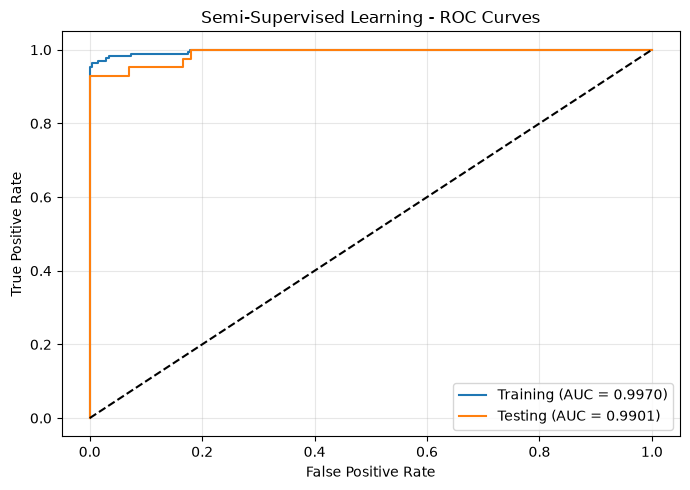

In [17]:
plot_roc_curves(
    semi_example,
    'Semi-Supervised Learning - ROC Curves'
)

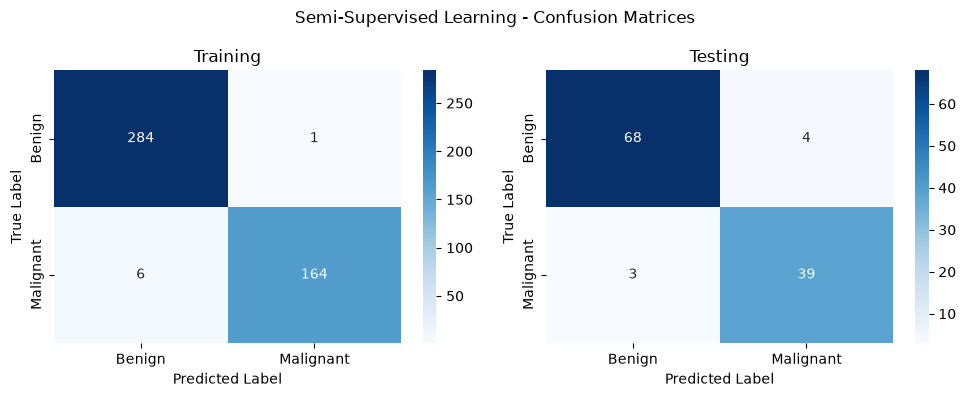

In [18]:
plot_confusion_matrices(
    semi_example,
    'Semi-Supervised Learning - Confusion Matrices'
)

**Interpretation:**

The semi-supervised model had an average training accuracy
of 97.76% and testing accuracy of 96.20% over 30 runs.
The average testing F1-score was 0.9472, and the AUC
was 0.9919.

In the first run, the model incorrectly classified 7 samples
in both the training and testing sets. Although the model
started with only half of the training labels, its results
were close to those of the supervised model. Supervised
learning still performed slightly better overall.

#### 1(b)(iii) Unsupervised Learning (K-Means)

I used K-means with k = 2 without using the true labels
during clustering. I used 50 random initializations and
kept the result with the lowest inertia to reduce the
chance of getting stuck in a local minimum.

In [19]:
def train_kmeans(X_train, y_train, seed):
    # Standardize the data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train)

    # Train K-means
    kmeans = KMeans(
        n_clusters=2,
        init='random',
        n_init=50,
        random_state=seed
    )

    kmeans.fit(X_scaled)

    # Distances to cluster centers
    distances = kmeans.transform(X_scaled)

    # Find the majority label for each cluster
    cluster_labels = {}

    for cluster in range(2):
        closest_indices = np.argsort(distances[:, cluster])[:30]
        closest_labels = y_train[closest_indices]

        cluster_labels[cluster] = np.bincount(
            closest_labels, minlength=2
        ).argmax()

    return scaler, kmeans, cluster_labels

In [20]:
def predict_kmeans(X_data, scaler, kmeans, cluster_labels):
    X_scaled = scaler.transform(X_data)

    # Predict clusters and assign class labels
    clusters = kmeans.predict(X_scaled)
    y_pred = np.array([cluster_labels[c] for c in clusters])

    # Calculate class scores for ROC and AUC
    distances = kmeans.transform(X_scaled)
    weights = np.exp(-(distances - distances.min(axis=1, keepdims=True)))
    probabilities = weights / weights.sum(axis=1, keepdims=True)

    y_score = np.zeros(len(X_data))

    for cluster in range(2):
        if cluster_labels[cluster] == 1:
            y_score += probabilities[:, cluster]

    return y_pred, y_score

In [21]:
kmeans_train_results = []
kmeans_test_results = []

for run in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=run
    )

    scaler, kmeans, cluster_labels = train_kmeans(
        X_train, y_train, run
    )

    # Training predictions
    y_train_pred, y_train_score = predict_kmeans(
        X_train, scaler, kmeans, cluster_labels
    )

    # Testing predictions
    y_test_pred, y_test_score = predict_kmeans(
        X_test, scaler, kmeans, cluster_labels
    )

    kmeans_train_results.append(
        calculate_metrics(y_train, y_train_pred, y_train_score)
    )

    kmeans_test_results.append(
        calculate_metrics(y_test, y_test_pred, y_test_score)
    )

    # Save the first run for plots
    if run == 0:
        kmeans_example = {
            'y_train': y_train,
            'y_train_pred': y_train_pred,
            'y_train_score': y_train_score,
            'y_test': y_test,
            'y_test_pred': y_test_pred,
            'y_test_score': y_test_score
        }

print("Completed all 30 K-means runs.")

Completed all 30 K-means runs.


In [22]:
kmeans_summary = pd.DataFrame({
    'Training': pd.DataFrame(kmeans_train_results).mean(),
    'Testing': pd.DataFrame(kmeans_test_results).mean()
})

display(kmeans_summary.round(4))

,Training,Testing
Accuracy,0.9102,0.9053
Precision,0.9238,0.9096
Recall,0.8282,0.8262
F1 Score,0.8732,0.8647
AUC,0.9749,0.9719


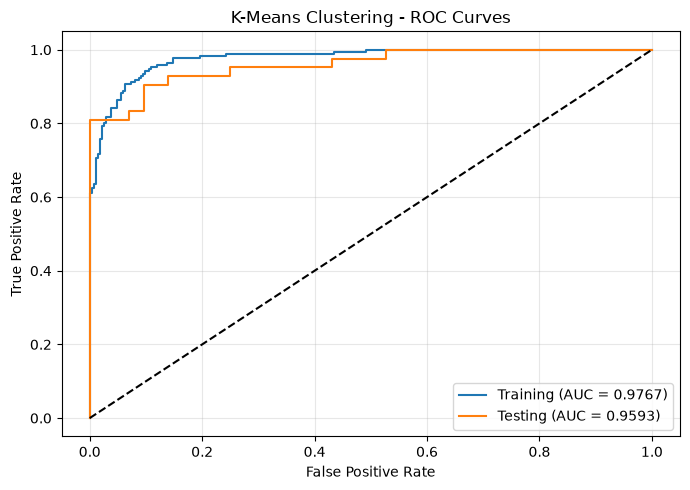

In [23]:
plot_roc_curves(
    kmeans_example,
    'K-Means Clustering - ROC Curves'
)

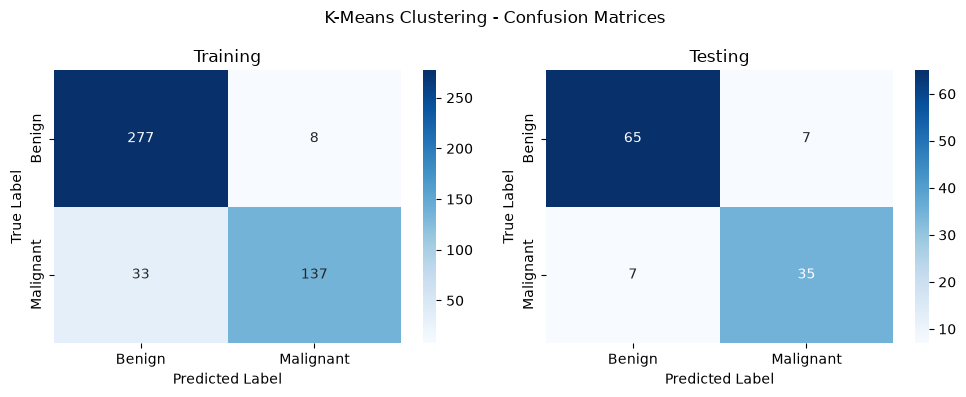

In [24]:
plot_confusion_matrices(
    kmeans_example,
    'K-Means Clustering - Confusion Matrices'
)

**Interpretation:**

K-means had an average training accuracy of 91.02%
and testing accuracy of 90.53% over 30 runs. The average
testing F1-score was 0.8647, and the AUC was 0.9719.

In the first run, K-means incorrectly classified 41 training
samples and 14 testing samples. It also misclassified more
malignant samples than the previous two models. This makes
sense because K-means groups samples based on their features
rather than learning directly from their true labels.

#### 1(b)(iv) Spectral Clustering

Spectral clustering groups samples based on their similarities
using a kernel. I used an RBF kernel with gamma = 1, as
specified in the assignment.

I also tested smaller gamma values, but none of the values
I tested produced clusters that exactly matched the original
class sizes. Therefore, I kept gamma = 1 for the final results.

In [75]:
def spectral_predict(X_data, seed):
    spectral = SpectralClustering(
        n_clusters=2,
        affinity='rbf',
        gamma=1,
        assign_labels='kmeans',
        n_init=50,
        random_state=seed
    )

    return spectral.fit_predict(X_data)


def spectral_majority_labels(clusters, y_true):
    cluster_labels = {}
    cluster_scores = {}

    for cluster in range(2):
        labels = y_true[clusters == cluster]

        cluster_labels[cluster] = np.bincount(
            labels, minlength=2
        ).argmax()

        cluster_scores[cluster] = np.mean(labels)

    return cluster_labels, cluster_scores

In [76]:
spectral_train_results = []
spectral_test_results = []

for run in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=run
    )

    # Standardize the data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Cluster the combined data
    X_combined = np.vstack([X_train_scaled, X_test_scaled])
    clusters = spectral_predict(X_combined, run)

    train_clusters = clusters[:len(X_train)]
    test_clusters = clusters[len(X_train):]

    # Assign labels using the training data
    cluster_labels, cluster_scores = spectral_majority_labels(
        train_clusters, y_train
    )

    # Training predictions and scores
    y_train_pred = np.array([
        cluster_labels[c] for c in train_clusters
    ])

    y_train_score = np.array([
        cluster_scores[c] for c in train_clusters
    ])

    # Testing predictions and scores
    y_test_pred = np.array([
        cluster_labels[c] for c in test_clusters
    ])

    y_test_score = np.array([
        cluster_scores[c] for c in test_clusters
    ])

    spectral_train_results.append(
        calculate_metrics(y_train, y_train_pred, y_train_score)
    )

    spectral_test_results.append(
        calculate_metrics(y_test, y_test_pred, y_test_score)
    )

    # Save the first run for plots
    if run == 0:
        spectral_example = {
            'y_train': y_train,
            'y_train_pred': y_train_pred,
            'y_train_score': y_train_score,
            'y_test': y_test,
            'y_test_pred': y_test_pred,
            'y_test_score': y_test_score
        }

    print(f"Run {run + 1}/{M} completed")

Run 1/30 completed
Run 2/30 completed
Run 3/30 completed
Run 4/30 completed
Run 5/30 completed
Run 6/30 completed
Run 7/30 completed
Run 8/30 completed
Run 9/30 completed
Run 10/30 completed
Run 11/30 completed
Run 12/30 completed
Run 13/30 completed
Run 14/30 completed
Run 15/30 completed
Run 16/30 completed
Run 17/30 completed
Run 18/30 completed
Run 19/30 completed
Run 20/30 completed
Run 21/30 completed
Run 22/30 completed
Run 23/30 completed
Run 24/30 completed
Run 25/30 completed
Run 26/30 completed
Run 27/30 completed
Run 28/30 completed
Run 29/30 completed
Run 30/30 completed


In [77]:
spectral_summary = pd.DataFrame({
    'Training': pd.DataFrame(spectral_train_results).mean(),
    'Testing': pd.DataFrame(spectral_test_results).mean()
})

display(spectral_summary.round(4))

,Training,Testing
Accuracy,0.6300,0.6348
Precision,1.0000,0.3667
Recall,0.0096,0.0087
F1 Score,0.0190,0.0171
AUC,0.5048,0.5044


**Selecting Gamma**

I tested several gamma values to see if the cluster sizes
would match the original class distribution of 357 benign
and 212 malignant samples.

Gamma = 0.001 produced clusters of 379 and 190 samples,
which were closer but did not match exactly. I decided
to use gamma = 1 for the final simulation since it is
one of the options given in the assignment.

The gamma exploration was done using the full dataset.

In [34]:
gamma_values = [0.00001, 0.0001, 0.0005, 0.001,
                0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 1]

X_scaled = StandardScaler().fit_transform(X)

print("Original class sizes:", np.bincount(y))

for gamma in gamma_values:
    spectral = SpectralClustering(
        n_clusters=2,
        affinity='rbf',
        gamma=gamma,
        assign_labels='kmeans',
        n_init=50,
        random_state=0
    )

    clusters = spectral.fit_predict(X_scaled)

    print(f"Gamma = {gamma}: {np.bincount(clusters)}")

Original class sizes: [357 212]
Gamma = 1e-05: [379 190]
Gamma = 0.0001: [379 190]
Gamma = 0.0005: [379 190]
Gamma = 0.001: [379 190]
Gamma = 0.005: [398 171]
Gamma = 0.01: [416 153]
Gamma = 0.02: [567   2]
Gamma = 0.05: [567   2]
Gamma = 0.1: [567   2]
Gamma = 0.5: [567   2]
Gamma = 1: [567   2]


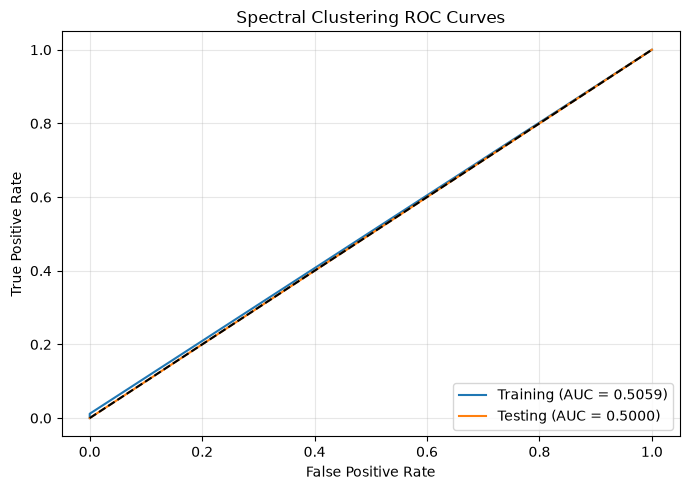

In [78]:
plot_roc_curves(spectral_example, "Spectral Clustering ROC Curves")

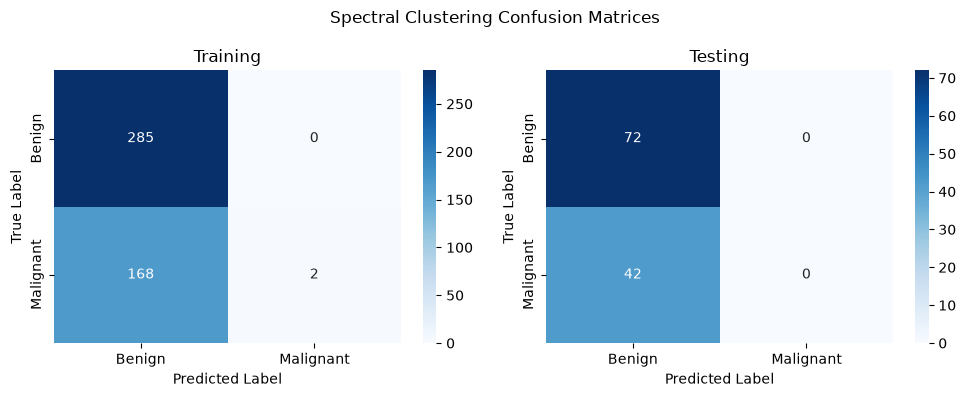

In [79]:
plot_confusion_matrices(
    spectral_example,
    "Spectral Clustering Confusion Matrices"
)

**Interpretation:**

Spectral clustering had an average training accuracy of
63.00% and testing accuracy of 63.48% over 30 runs.
The average testing F1-score was 0.0171, and the AUC
was 0.5044.

Most samples were classified as benign. In the first run,
none of the 42 malignant test samples were classified
correctly. The low recall and AUC show that gamma = 1
did not separate the two classes well.

The ROC curves have fewer points because each cluster
is assigned a single score based on its proportion of
malignant samples.

Since fit_predict() was used on the combined training
and testing features, the testing results are not from
a completely independent test set. Only training labels
were used to assign the cluster predictions.

#### 1(b)(v) Comparison of Learning Methods

The tables below compare the average training and testing
results of all four learning methods over 30 Monte Carlo runs.

In [80]:
training_comparison = pd.DataFrame({
    'Supervised SVM': supervised_summary['Training'],
    'Semi-Supervised SVM': semi_summary['Training'],
    'K-Means': kmeans_summary['Training'],
    'Spectral Clustering': spectral_summary['Training']
})

print("Average Training Results")
display(training_comparison.round(4))

Average Training Results


,Supervised SVM,Semi-Supervised SVM,K-Means,Spectral Clustering
Accuracy,0.9853,0.9776,0.9102,0.6300
Precision,0.9912,0.9818,0.9238,1.0000
Recall,0.9694,0.9580,0.8282,0.0096
F1 Score,0.9802,0.9696,0.8732,0.0190
AUC,0.9972,0.9948,0.9749,0.5048


In [81]:
testing_comparison = pd.DataFrame({
    'Supervised SVM': supervised_summary['Testing'],
    'Semi-Supervised SVM': semi_summary['Testing'],
    'K-Means': kmeans_summary['Testing'],
    'Spectral Clustering': spectral_summary['Testing']
})

print("Average Testing Results")
display(testing_comparison.round(4))

Average Testing Results


,Supervised SVM,Semi-Supervised SVM,K-Means,Spectral Clustering
Accuracy,0.9678,0.9620,0.9053,0.6348
Precision,0.9727,0.9695,0.9096,0.3667
Recall,0.9397,0.9270,0.8262,0.0087
F1 Score,0.9555,0.9472,0.8647,0.0171
AUC,0.9937,0.9919,0.9719,0.5044


**Comparison and Conclusion:**

Looking at the results, supervised SVM performed the best
with a testing accuracy of 96.78%. Semi-supervised SVM was
very close at 96.20%, even though it started with only half
of the training labels.

K-means performed fairly well with a testing accuracy of
90.53%, while spectral clustering performed the worst
with a testing accuracy of 63.48%. With gamma = 1,
spectral clustering classified most samples as benign
and struggled to identify malignant samples.

As expected, both SVM methods performed better than the
clustering methods since they had access to labels during
training.

Spectral clustering used both training and testing features,
so its testing results should be compared with some caution.

Overall, I found it interesting how close the semi-supervised
results were to the supervised results despite starting
with fewer labeled samples.

## 2. Active Learning Using Support Vector Machines

### 2(a) Loading and Splitting the Dataset

In [39]:
banknote_columns = [
    'Variance',
    'Skewness',
    'Curtosis',
    'Entropy',
    'Class'
]

banknote_df = pd.read_csv(
    'data/data_banknote_authentication.txt',
    header=None,
    names=banknote_columns
)

display(banknote_df.head())

,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [40]:
print("Dataset shape:", banknote_df.shape)

print("\nClass distribution:")
print(banknote_df['Class'].value_counts())

print("\nMissing values:")
print(banknote_df.isnull().sum())

Dataset shape: (1372, 5)

Class distribution:
Class
0    762
1    610
Name: count, dtype: int64

Missing values:
Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64


In [41]:
X_banknote = banknote_df.drop(columns=['Class']).to_numpy()
y_banknote = banknote_df['Class'].to_numpy()

X_bank_train, X_bank_test, y_bank_train, y_bank_test = train_test_split(
    X_banknote,
    y_banknote,
    test_size=472,
    random_state=42
)

print("Training set:", X_bank_train.shape)
print("Testing set:", X_bank_test.shape)

print("\nTraining class distribution:", np.bincount(y_bank_train))
print("Testing class distribution:", np.bincount(y_bank_test))

Training set: (900, 4)
Testing set: (472, 4)

Training class distribution: [496 404]
Testing class distribution: [266 206]


### 2(b)(i) Passive Learning

I started with a pool of 10 randomly selected training
samples and added 10 more samples at each step without
replacement. I used 5-fold cross-validation to select
the penalty parameter and calculated the test error
after each step.

In [67]:
C_values_banknote = np.logspace(-3, 2, 11)

def train_banknote_svm(X_pool, y_pool, seed):
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', LinearSVC(
            penalty='l1',
            loss='squared_hinge',
            dual=False,
            max_iter=1000000,
            tol=1e-2,
            random_state=seed
        ))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    grid = GridSearchCV(
        pipeline,
        param_grid={'svm__C': C_values_banknote},
        cv=cv,
        scoring='accuracy',
        n_jobs=1
    )

    grid.fit(X_pool, y_pool)

    if grid.best_estimator_.named_steps['svm'].n_iter_ >= 1000000:
        print("Final selected SVM did not converge")

    return grid.best_estimator_


In [59]:
def initial_pool(y_train, rng):
    class_0 = np.where(y_train == 0)[0]
    class_1 = np.where(y_train == 1)[0]

    selected = np.concatenate([
        rng.choice(class_0, 5, replace=False),
        rng.choice(class_1, 5, replace=False)
    ])

    return selected

In [60]:
def passive_learning(X_train, y_train, X_test, y_test, seed):
    rng = np.random.default_rng(seed)

    selected = initial_pool(y_train, rng)
    remaining = np.setdiff1d(np.arange(len(X_train)), selected)

    errors = []

    for size in range(10, 901, 10):

        # Train the SVM
        model = train_banknote_svm(
            X_train[selected], y_train[selected], seed
        )

        # Calculate test error
        y_pred = model.predict(X_test)
        error = 1 - accuracy_score(y_test, y_pred)
        errors.append(error)

        # Add 10 random samples
        if len(remaining) > 0:
            new_samples = rng.choice(
                remaining, 10, replace=False
            )

            selected = np.concatenate([selected, new_samples])
            remaining = np.setdiff1d(remaining, new_samples)

    return errors

I randomly selected five samples from each class for
the initial pool so that 5-fold cross-validation could
be used. The remaining samples were added randomly
without replacement.

In [74]:
import time

In [69]:
passive_results = []

start = time.time()

for run in range(50):
    errors = passive_learning(
        X_bank_train,
        y_bank_train,
        X_bank_test,
        y_bank_test,
        seed=run
    )

    passive_results.append(errors)

    if (run + 1) % 5 == 0:
        print(f"Run {run + 1}/50 completed")

passive_results = np.array(passive_results)

print("\nResults shape:", passive_results.shape)
print("Total runtime:", round(time.time() - start, 2), "seconds")

Run 5/50 completed
Run 10/50 completed
Run 15/50 completed
Run 20/50 completed
Run 25/50 completed
Run 30/50 completed
Run 35/50 completed
Run 40/50 completed
Run 45/50 completed
Run 50/50 completed

Results shape: (50, 90)
Total runtime: 336.14 seconds


### 2(b)(ii) Active Learning

For active learning, I started with 10 training samples.
Instead of adding samples randomly, I selected the 10
samples closest to the SVM decision boundary at each step.
I then retrained the model and calculated the test error.

In [62]:
def active_learning(X_train, y_train, X_test, y_test, seed):
    rng = np.random.default_rng(seed)

    selected = initial_pool(y_train, rng)
    remaining = np.setdiff1d(np.arange(len(X_train)), selected)

    errors = []

    for size in range(10, 901, 10):

        # Train the SVM
        model = train_banknote_svm(
            X_train[selected], y_train[selected], seed
        )

        # Calculate test error
        y_pred = model.predict(X_test)
        error = 1 - accuracy_score(y_test, y_pred)
        errors.append(error)

        # Select 10 samples closest to the decision boundary
        if len(remaining) > 0:
            distances = np.abs(
                model.decision_function(X_train[remaining])
            )

            closest = np.argsort(distances)[:10]
            new_samples = remaining[closest]

            selected = np.concatenate([selected, new_samples])
            remaining = np.setdiff1d(remaining, new_samples)

    return errors

In [70]:
active_results = []

start = time.time()

for run in range(50):
    errors = active_learning(
        X_bank_train,
        y_bank_train,
        X_bank_test,
        y_bank_test,
        seed=run
    )

    active_results.append(errors)

    if (run + 1) % 5 == 0:
        print(f"Run {run + 1}/50 completed")

active_results = np.array(active_results)

print("\nResults shape:", active_results.shape)
print("Total runtime:", round(time.time() - start, 2), "seconds")

/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tin

Run 5/50 completed


/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tin

Run 10/50 completed


/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tin

Run 15/50 completed


... (10 outputs left out)

/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Run 45/50 completed


/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tinaarezoomanian/Library/Python/3.12/lib/python/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/tin

Run 50/50 completed

Results shape: (50, 90)
Total runtime: 360.96 seconds


### 2(c) Learning Curves

I averaged the test errors from all 50 runs for each
training pool size and plotted the results to compare
active and passive learning.

In [71]:
pool_sizes = np.arange(10, 901, 10)

passive_avg_errors = passive_results.mean(axis=0)
active_avg_errors = active_results.mean(axis=0)

print("Passive learning:", passive_avg_errors.shape)
print("Active learning:", active_avg_errors.shape)

Passive learning: (90,)
Active learning: (90,)


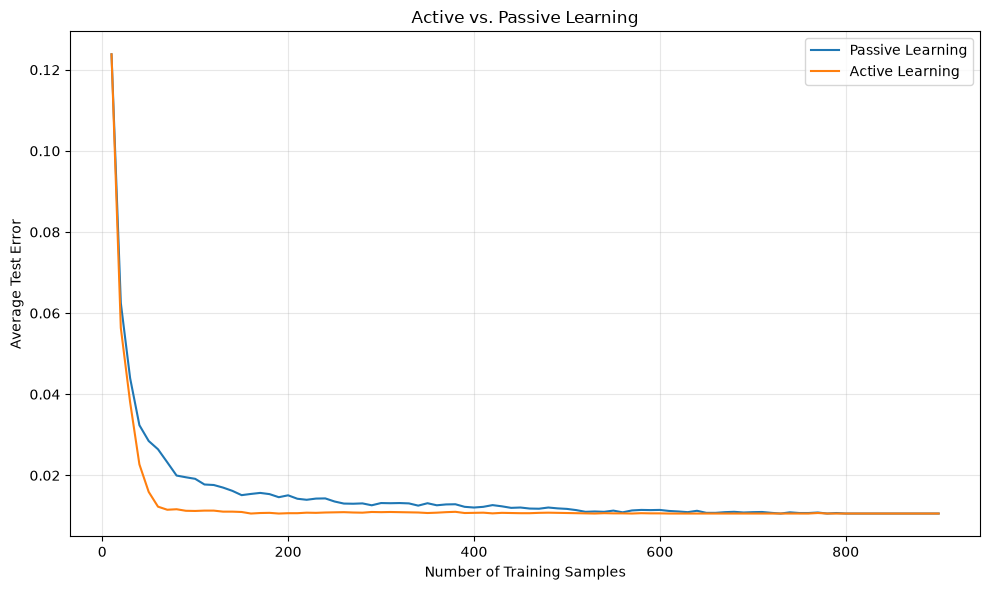

In [72]:
plt.figure(figsize=(10, 6))

plt.plot(pool_sizes, passive_avg_errors, label='Passive Learning')
plt.plot(pool_sizes, active_avg_errors, label='Active Learning')

plt.xlabel('Number of Training Samples')
plt.ylabel('Average Test Error')
plt.title('Active vs. Passive Learning')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [73]:
comparison = pd.DataFrame({
    'Training Samples': pool_sizes,
    'Passive Learning': passive_avg_errors,
    'Active Learning': active_avg_errors
})

display(comparison.iloc[[0, 4, 5, 9, 19, 49, 89]].round(4))

,Training Samples,Passive Learning,Active Learning
0,10,0.1238,0.1238
4,50,0.0285,0.0159
5,60,0.0264,0.0123
9,100,0.0192,0.0112
19,200,0.0151,0.0107
49,500,0.0117,0.0107
89,900,0.0106,0.0106


**Conclusion:**

Both methods started with the same average test error of
12.38%, but active learning reduced the error much faster.

With 60 training samples, active learning had a test error
of 1.23%, while passive learning had an error of 2.64%.
As more samples were added, the difference between the
two methods became smaller.

Once all 900 samples were used, both methods had the same
test error of 1.06%.

Overall, active learning was more efficient because it
selected samples closest to the decision boundary instead
of selecting them randomly.

Some convergence warnings occurred during cross-validation,
even after increasing the maximum number of iterations.
None of the final selected models reached the iteration
limit, but the warnings may have affected the choice of C.